# Credit Risk Prediction & Default Analysis
**Role:** Machine Learning Analyst  |  **Data:** `credit.csv` (1,000 historical loan applicants)

## Business problem
The bank's main risk is **credit default**: a borrower who stops paying. We build a classifier that labels each
applicant as a **good** loan (`default = 0`) or a **defaulting** loan (`default = 1`), so that high-risk
applications can be caught *before* money is lent, without turning away good customers unnecessarily.

## How this notebook is organised
1. Setup
2. Load data and audit its quality
3. Exploratory data analysis (EDA)
4. Preprocessing (cleaning, encoding, scaling, train/test split)
5. Model training, comparison, tuning and evaluation
6. Sensitive attributes: does the model need them?
7. Business impact and recommendations

## Conventions used throughout
* The **positive class is `default = 1`**. *Recall* therefore means "what share of real defaulters did we catch".
* Accuracy is **not** the headline metric. With 30% defaults, a model that approves everybody is already 70% "accurate".
  We focus on **Recall**, **F1** and **AUC-ROC**, as the project brief requires.
* Every learned step (imputation, scaling, encoding) lives inside a scikit-learn `Pipeline`, so it is fitted on
  training data only. This prevents information from the test set leaking into the model.

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')          # keep the notebook output readable
RANDOM_STATE = 42                          # fixed seed so every run gives the same numbers
TARGET = 'default'                         # 1 = defaulting loan (positive class), 0 = good loan

FIG_DIR, RES_DIR = Path('figures'), Path('results')   # charts / tables are saved here for the slide deck
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

In [2]:
# Visual style: one place to change colours. Blue = good loan, orange = default (used consistently in every chart).
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA, YELLOW, RED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e34948'
CLASS_COLORS = {0: BLUE, 1: ORANGE}
CLASS_NAMES = {0: 'Good loan', 1: 'Default'}

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'text.color': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.grid': True, 'axes.grid.axis': 'x', 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 100,
})
SEQ_BLUE = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#3987e5', '#0d366b'])
DIV_BLUE_RED = LinearSegmentedColormap.from_list('div_blue_red', [BLUE, '#f0efec', RED])


def finish(name=None, rect=None):
    """Tidy the current figure, save a copy for the slide deck (if named), then display it."""
    plt.tight_layout(rect=rect) if rect else plt.tight_layout()
    if name:
        plt.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()


def pct_axis(ax, axis='x'):
    """Format an axis as percentages."""
    fmt = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
    (ax.xaxis if axis == 'x' else ax.yaxis).set_major_formatter(fmt)

## 2. Load data and audit its quality

In [3]:
df = pd.read_csv('credit.csv')
print(f'{df.shape[0]:,} applicants, {df.shape[1]} columns')
df.head()

1,000 applicants, 23 columns


,observation_id,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,residence_history,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job,gender
0,0,-43.0,6,critical,radio/tv,1169,NaN,13 years,4,single,none,6 years,real estate,67,none,own,2,0,1,2.349340e+09,yes,skilled employee,male
1,1,75.0,48,repaid,radio/tv,5951,89.0,2 years,2,NaN,none,5 months,real estate,22,none,own,1,1,1,NaN,yes,skilled employee,female
2,2,NaN,12,critical,education,2096,24.0,5 years,2,single,none,4 years,real estate,49,none,own,1,0,2,NaN,yes,unskilled resident,male
3,3,-32.0,42,repaid,furniture,7882,9.0,5 years,2,single,guarantor,13 years,building society savings,45,none,for free,1,0,2,NaN,yes,skilled employee,male
4,4,-23.0,24,delayed,car (new),4870,43.0,3 years,3,single,none,13 years,unknown/none,53,none,for free,2,1,2,NaN,yes,skilled employee,male


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   observation_id        1000 non-null   int64  
 1   checking_balance      606 non-null    float64
 2   months_loan_duration  1000 non-null   int64  
 3   credit_history        1000 non-null   str    
 4   purpose               1000 non-null   str    
 5   amount                1000 non-null   int64  
 6   savings_balance       817 non-null    float64
 7   employment_length     938 non-null    str    
 8   installment_rate      1000 non-null   int64  
 9   personal_status       690 non-null    str    
 10  other_debtors         1000 non-null   str    
 11  residence_history     870 non-null    str    
 12  property              1000 non-null   str    
 13  age                   1000 non-null   int64  
 14  installment_plan      1000 non-null   str    
 15  housing               1000 non-nu

### 2.1 Missing values, duplicates and identifiers

In [5]:
missing = (df.isna().sum().rename('n_missing').to_frame()
             .assign(pct_missing=lambda d: (d.n_missing / len(df) * 100).round(1))
             .query('n_missing > 0')
             .sort_values('n_missing', ascending=False))
print('Duplicate rows:', df.duplicated().sum(), '| observation_id is unique:', df['observation_id'].is_unique)
missing

Duplicate rows: 0 | observation_id is unique: True


,n_missing,pct_missing
telephone,596,59.6
checking_balance,394,39.4
personal_status,310,31.0
savings_balance,183,18.3
residence_history,130,13.0
employment_length,62,6.2


Six columns contain missing values, some of them a lot (`telephone` 60%, `checking_balance` 39%).
Before deciding how to treat them we need to understand *why* they are missing, which is done in section 3.2.

### 2.2 Columns that need cleaning
Several columns are not in a model-ready format. Printing a few raw values shows the problem:

In [6]:
print('employment_length :', df['employment_length'].dropna().sample(8, random_state=1).tolist())
print('residence_history :', df['residence_history'].dropna().sample(8, random_state=1).tolist())
print('telephone         :', df['telephone'].dropna().head(3).tolist())
print('credit_history    :', sorted(df['credit_history'].unique()))

employment_length : ['2 years', '1 years', '6 years', '2 years', '2 years', '1 months', '19 years', '1 years']
residence_history : ['18 years', '22 years', '11 months', '18 years', '2 years', '5 months', '0 months', '22 years']
telephone         : [2349339647.0, 2345787903.0, 2349961683.0]
credit_history    : ['critical', 'delayed', 'fully repaid', 'fully repaid this bank', 'repaid']


* `employment_length` and `residence_history` are text and mix **months and years** ("8 months", "13 years").
  They are converted to one numeric unit (months).
* `telephone` holds actual phone numbers. The number itself is an identifier and carries no meaning, so it is
  reduced to a yes/no flag `has_phone`.
* `amount` and `savings_balance` are strongly right-skewed, so a log transform (`log1p`) is added for them.
* `monthly_amount` (loan amount ÷ duration) is a simple proxy for the size of each repayment.
* `observation_id` is only a row label and is dropped.

All of this is done by one function so that exactly the same logic can later be applied to new applicants.

In [7]:
def to_months(value):
    """Convert strings such as '13 years' or '8 months' to a number of months (missing stays missing)."""
    if pd.isna(value):
        return np.nan
    number, unit = str(value).split()
    return float(number) * (12 if unit.startswith('year') else 1)


def engineer_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Row-wise cleaning and feature creation. Nothing here is learned from the data, so it is safe before splitting."""
    d = raw.copy()
    d['employment_months'] = d['employment_length'].map(to_months)
    d['residence_months'] = d['residence_history'].map(to_months)
    d['has_phone'] = d['telephone'].notna().astype(int)
    # personal_status is empty for exactly the female applicants (shown in section 3.3), so give it an explicit label
    d['personal_status'] = d['personal_status'].fillna('female - not recorded')
    d['log_amount'] = np.log1p(d['amount'])
    d['log_savings'] = np.log1p(d['savings_balance'])
    d['monthly_amount'] = d['amount'] / d['months_loan_duration']
    return d.drop(columns=['observation_id', 'telephone', 'employment_length', 'residence_history'])


data = engineer_features(df)
data[['employment_months', 'residence_months', 'has_phone', 'log_amount', 'monthly_amount']].describe().round(2)

,employment_months,residence_months,has_phone,log_amount,monthly_amount
count,938.00,870.00,1000.00,1000.00,1000.00
mean,63.24,90.56,0.40,7.79,167.69
std,63.47,94.92,0.49,0.78,153.49
min,0.00,0.00,0.00,5.53,24.06
25%,12.00,8.00,0.00,7.22,89.60
50%,36.00,48.00,0.00,7.75,130.33
75%,93.00,168.00,1.00,8.29,206.18
max,228.00,288.00,1.00,9.82,2482.67


## 3. Exploratory data analysis (EDA)
### 3.1 Class balance

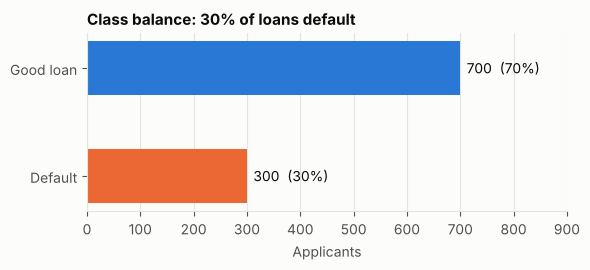

In [8]:
counts = data[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh([CLASS_NAMES[i] for i in counts.index], counts.values,
        color=[CLASS_COLORS[i] for i in counts.index], height=0.5)
for pos, v in enumerate(counts.values):
    ax.text(v + 12, pos, f'{v:,}  ({v / len(data):.0%})', va='center', color=INK)
ax.set(xlim=(0, 900), xlabel='Applicants', title=f'Class balance: {data[TARGET].mean():.0%} of loans default')
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
finish('01_class_balance')

### 3.2 Is "missing" a meaningful value?
If missing values are random, we could simply fill them in. If they carry information, filling them blindly would
throw that information away. We compare the default rate of applicants **with** and **without** a value, per column.

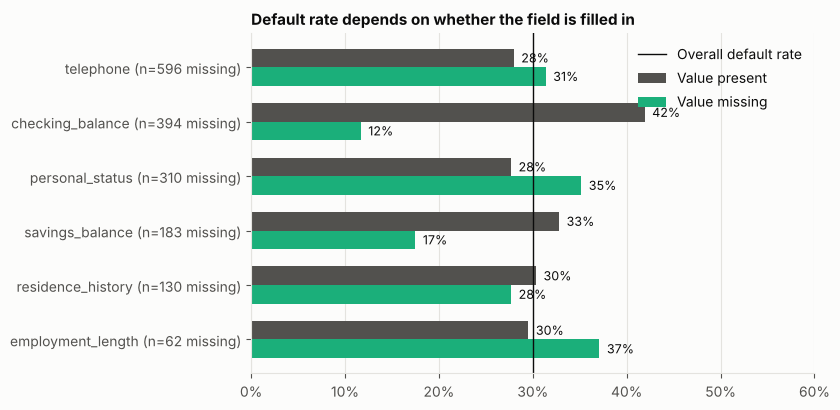

In [9]:
rows = []
for col in missing.index:
    rate = df.groupby(df[col].isna())[TARGET].mean()      # raw data: the cleaned copy no longer has these columns
    rows.append({'column': col, 'n_missing': int(df[col].isna().sum()),
                 'default_rate_if_present': rate[False], 'default_rate_if_missing': rate[True]})
miss_rate = pd.DataFrame(rows).set_index('column')

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(miss_rate))
h = 0.34
ax.barh(y - h / 2, miss_rate['default_rate_if_present'], h, color=INK_2, label='Value present')
ax.barh(y + h / 2, miss_rate['default_rate_if_missing'], h, color=AQUA, label='Value missing')
ax.axvline(data[TARGET].mean(), color=INK, lw=1, label='Overall default rate')
for pos, (p, m) in enumerate(zip(miss_rate['default_rate_if_present'], miss_rate['default_rate_if_missing'])):
    ax.text(p + 0.008, pos - h / 2, f'{p:.0%}', va='center', fontsize=9)
    ax.text(m + 0.008, pos + h / 2, f'{m:.0%}', va='center', fontsize=9)
ax.set_yticks(y, [f'{c} (n={n:,} missing)' for c, n in zip(miss_rate.index, miss_rate['n_missing'])])
ax.set(xlim=(0, 0.6), title='Default rate depends on whether the field is filled in')
pct_axis(ax)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(loc='upper right')
finish('02_missingness_vs_default')

### 3.3 `personal_status` versus `gender`

In [10]:
pd.crosstab(df['gender'], df['personal_status'].fillna('(missing)'))

personal_status,(missing),divorced,married,single
gender,,,,
female,310,0,0,0
male,0,50,92,548


### 3.4 Numeric features and default

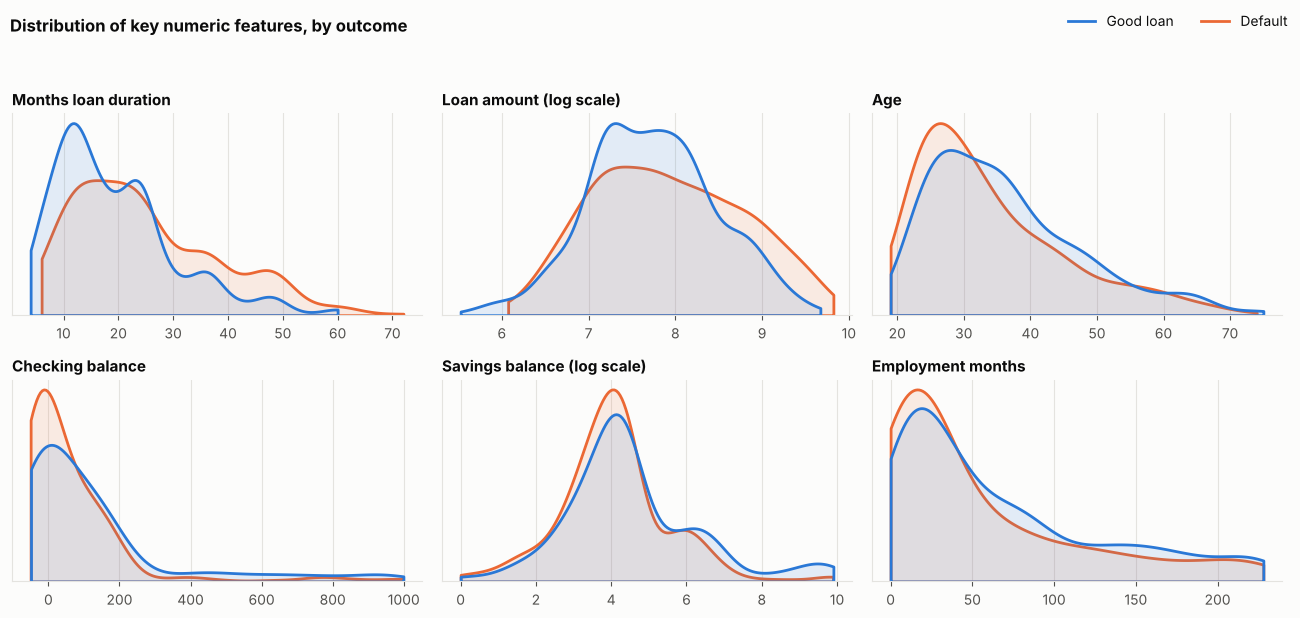

In [11]:
# amount and savings are plotted on a log scale (log1p) because a few very large values squash the raw charts
num_cols = ['months_loan_duration', 'log_amount', 'age', 'checking_balance', 'log_savings', 'employment_months']
num_titles = {'log_amount': 'Loan amount (log scale)', 'log_savings': 'Savings balance (log scale)'}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, col in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=data, x=col, hue=TARGET, palette=CLASS_COLORS, common_norm=False, fill=True,
                alpha=0.12, linewidth=2, cut=0, legend=False, ax=ax)
    ax.set(title=num_titles.get(col, col.replace('_', ' ').capitalize()), xlabel='', ylabel='')
    ax.set_yticks([])
handles = [plt.Line2D([0], [0], color=CLASS_COLORS[k], lw=2, label=CLASS_NAMES[k]) for k in (0, 1)]
fig.legend(handles=handles, loc='upper right', ncol=2)
fig.suptitle('Distribution of key numeric features, by outcome', x=0.01, ha='left', fontweight='bold')
finish('03_numeric_distributions', rect=[0, 0, 1, 0.94])

### 3.5 Outliers
Outliers are flagged with the standard IQR rule (values beyond 1.5 × the inter-quartile range from the quartiles).

In [12]:
def iqr_summary(s: pd.Series) -> pd.Series:
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = int(((s < lo) | (s > hi)).sum())
    return pd.Series({'n_outliers': n_out, 'pct_outliers': round(n_out / len(s) * 100, 1),
                      'lower_fence': round(lo, 1), 'upper_fence': round(hi, 1), 'max': round(s.max(), 1)})


out_cols = ['months_loan_duration', 'amount', 'age', 'checking_balance', 'savings_balance',
            'employment_months', 'residence_months', 'monthly_amount']
outliers = pd.DataFrame({c: iqr_summary(data[c].dropna()) for c in out_cols}).T
outliers

,n_outliers,pct_outliers,lower_fence,upper_fence,max
months_loan_duration,70.0,7.0,-6.0,42.0,72.0
amount,72.0,7.2,-2544.6,7882.4,18424.0
age,23.0,2.3,4.5,64.5,75.0
checking_balance,55.0,9.1,-255.1,363.9,999.0
savings_balance,173.0,21.2,-114.5,273.5,19972.0
employment_months,44.0,4.7,-109.5,214.5,228.0
residence_months,0.0,0.0,-232.0,408.0,288.0
monthly_amount,45.0,4.5,-85.3,381.1,2482.7


Ten largest checking_balance values: [999.0, 997.0, 992.0, 989.0, 979.0, 975.0, 935.0, 927.0, 927.0, 926.0]


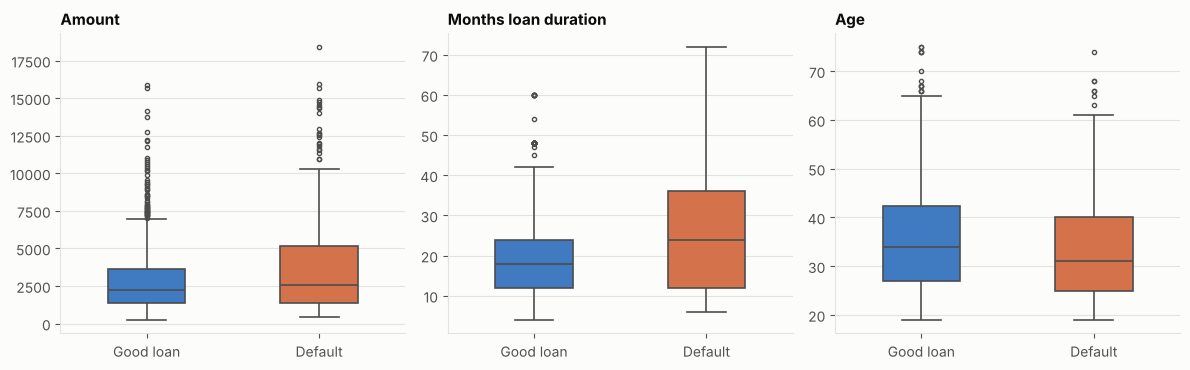

In [13]:
print('Ten largest checking_balance values:', data['checking_balance'].nlargest(10).tolist())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, col in zip(axes, ['amount', 'months_loan_duration', 'age']):
    sns.boxplot(data=data, x=TARGET, y=col, hue=TARGET, palette=CLASS_COLORS, width=0.45, linewidth=1.2,
                fliersize=3, legend=False, ax=ax)
    ax.set_xticks([0, 1], ['Good loan', 'Default'])
    ax.set(xlabel='', ylabel='', title=col.replace('_', ' ').capitalize())
    ax.grid(axis='x', visible=False)
    ax.grid(axis='y', visible=True)
finish('04_outlier_boxplots')

### 3.6 Categorical features and default rate
Each bar is the share of applicants in that category who defaulted. The black line is the overall default rate.
The count in brackets shows how many applicants the bar is based on, so small groups should be read with care.

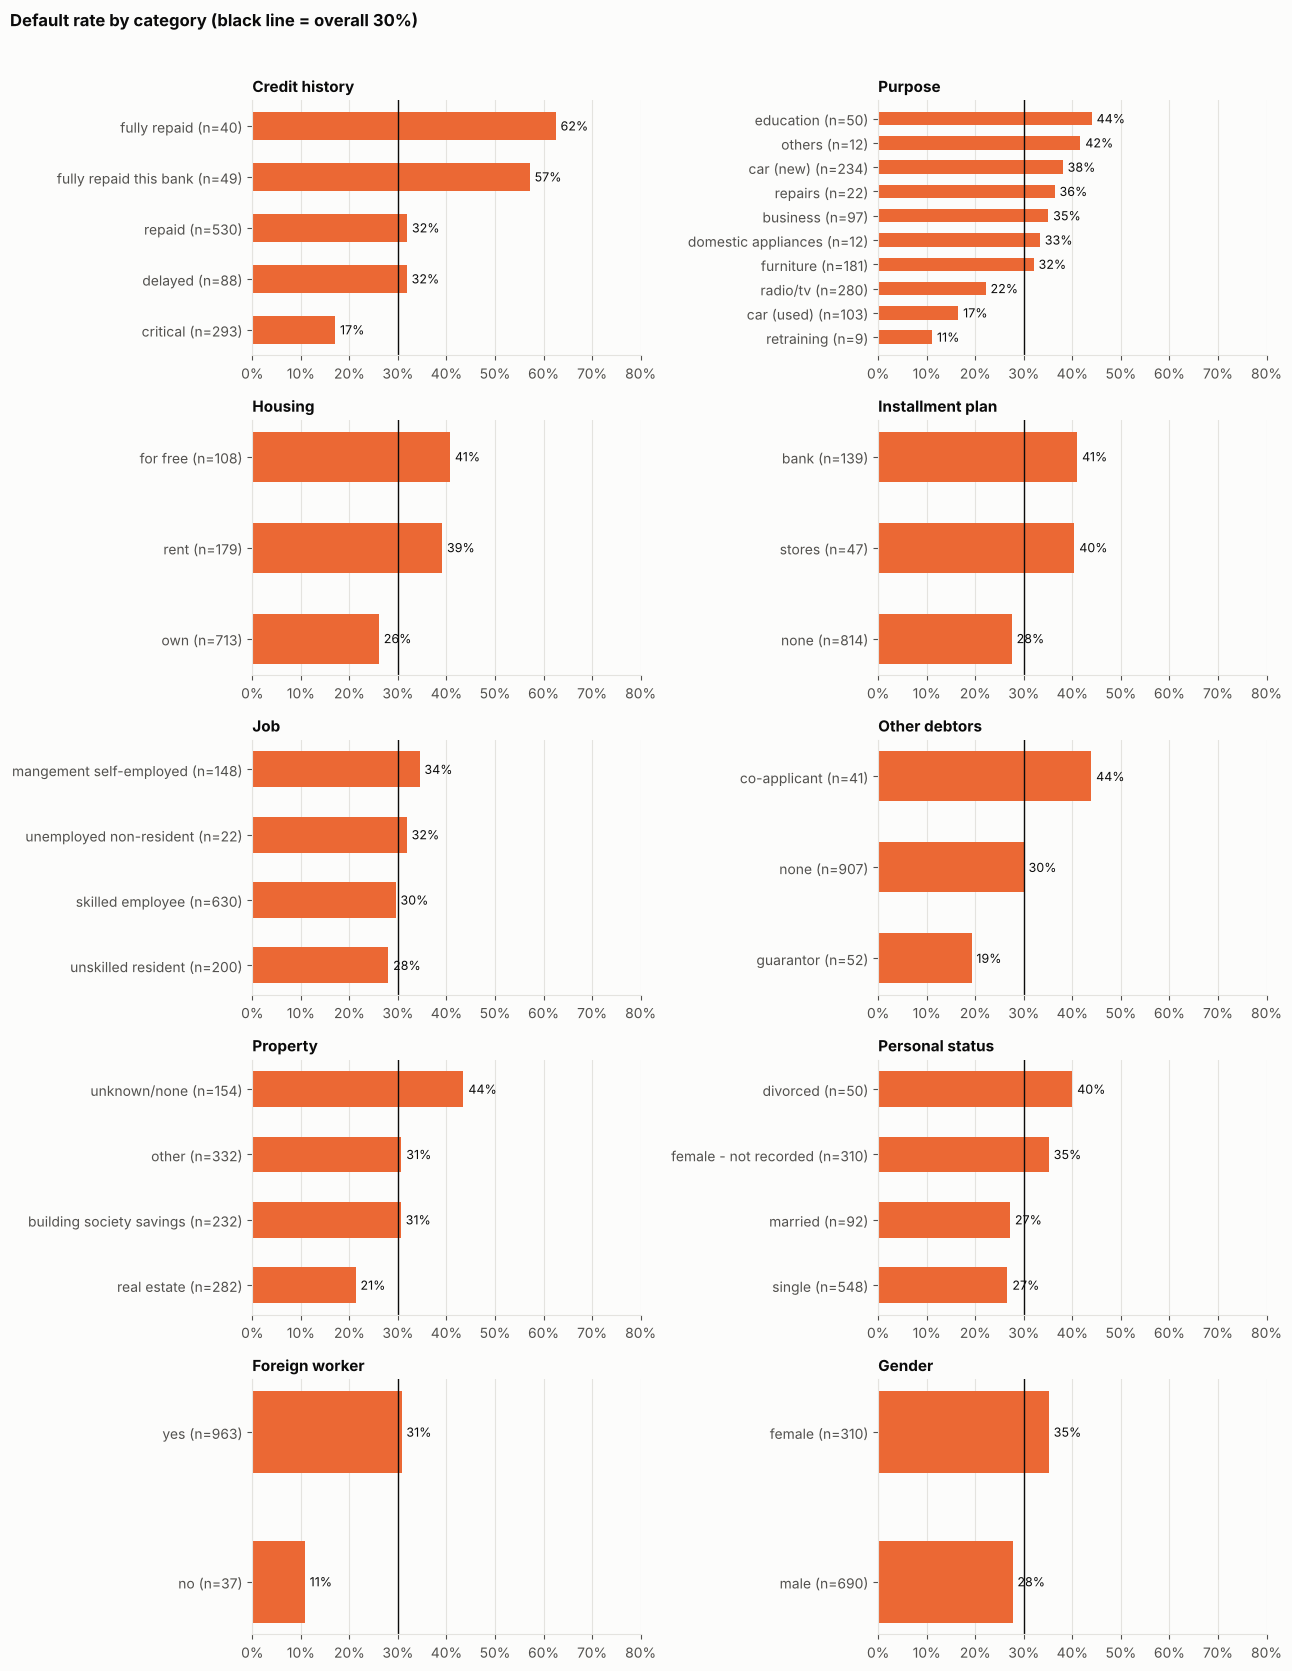

In [14]:
cat_cols = ['credit_history', 'purpose', 'housing', 'installment_plan', 'job',
            'other_debtors', 'property', 'personal_status', 'foreign_worker', 'gender']
overall = data[TARGET].mean()
fig, axes = plt.subplots(5, 2, figsize=(13, 17))
for ax, col in zip(axes.ravel(), cat_cols):
    g = data.groupby(col)[TARGET].agg(['mean', 'count']).sort_values('mean')
    ax.barh([f'{i} (n={n})' for i, n in zip(g.index, g['count'])], g['mean'], color=ORANGE, height=0.55)
    ax.axvline(overall, color=INK, lw=1)
    for pos, v in enumerate(g['mean']):
        ax.text(v + 0.01, pos, f'{v:.0%}', va='center', fontsize=9)
    ax.set(xlim=(0, 0.8), title=col.replace('_', ' ').capitalize())
    pct_axis(ax)
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Default rate by category (black line = overall {overall:.0%})', x=0.01, ha='left', fontweight='bold')
finish('05_default_rate_by_category', rect=[0, 0, 1, 0.97])

### 3.7 Correlations between numeric features

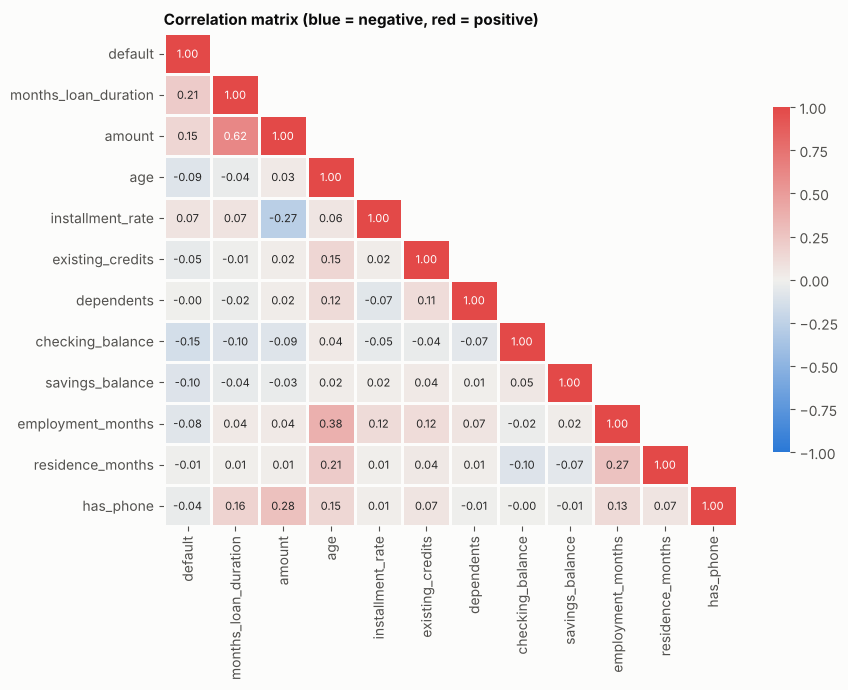

checking_balance       -0.148
savings_balance        -0.097
age                    -0.091
employment_months      -0.082
existing_credits       -0.046
has_phone              -0.036
residence_months       -0.014
dependents             -0.003
installment_rate        0.072
amount                  0.155
months_loan_duration    0.215
Name: default, dtype: float64

In [15]:
corr_cols = [TARGET, 'months_loan_duration', 'amount', 'age', 'installment_rate', 'existing_credits',
             'dependents', 'checking_balance', 'savings_balance', 'employment_months', 'residence_months', 'has_phone']
corr = data[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, cmap=DIV_BLUE_RED, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 8}, linewidths=2, linecolor=SURFACE, cbar_kws={'shrink': 0.7}, ax=ax)
ax.set_title('Correlation matrix (blue = negative, red = positive)')
ax.grid(False)
finish('06_correlation_heatmap')

corr[TARGET].drop(TARGET).sort_values().round(3)

## 4. Data preprocessing

### 4.1 Missing values: the decisions
| Column | Decision | Why |
|---|---|---|
| `checking_balance`, `savings_balance` | Fill with the training **median** *and* add a "was missing" indicator column | Missing is informative (section 3.2), so the indicator lets the model use it. The median keeps the numeric column usable. |
| `employment_months`, `residence_months` | Same: median + indicator | Same reasoning, and the amount of missing data is small. |
| `personal_status` | Explicit label `female - not recorded` | It is missing for exactly the 310 female applicants (section 3.3). |
| `telephone` | Converted to `has_phone` (0/1) | Missing means "no phone on file". The number itself is meaningless. |

The median and indicator logic is **learned from the training set only** (inside the pipeline), never from the test set.

### 4.2 Feature lists

In [16]:
NUMERIC = ['months_loan_duration', 'log_amount', 'monthly_amount', 'installment_rate', 'age',
           'existing_credits', 'dependents', 'checking_balance', 'log_savings',
           'employment_months', 'residence_months', 'has_phone']
CATEGORICAL = ['credit_history', 'purpose', 'other_debtors', 'property', 'installment_plan',
               'housing', 'job', 'foreign_worker', 'gender', 'personal_status']
FEATURES = NUMERIC + CATEGORICAL

X = data[FEATURES]
y = data[TARGET]
loan_amount = data['amount']          # kept aside (not a model input) to express results in money terms later
print(f'{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical = {len(FEATURES)} input features')

12 numeric + 10 categorical = 22 input features


### 4.3 Train / test split
80% of applicants are used to build and tune models, 20% are locked away to give an honest final score.
The split is **stratified**, so both parts keep the same 30% default rate.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {len(X_train)} rows, default rate {y_train.mean():.1%}')
print(f'Test : {len(X_test)} rows, default rate {y_test.mean():.1%}')

Train: 800 rows, default rate 30.0%
Test : 200 rows, default rate 30.0%


### 4.4 Encoding and scaling
* **Numeric:** median imputation (+ missing indicator) → standardisation (mean 0, std 1). Scaling matters for
  Logistic Regression and SVM, and does no harm to tree models.
* **Categorical:** one-hot encoding (each category becomes a 0/1 column). Categories never seen in training are ignored safely.

In [18]:
def build_preprocessor(numeric, categorical):
    """Imputation + scaling for numbers, imputation + one-hot encoding for categories."""
    numeric_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([('num', numeric_pipe, numeric), ('cat', categorical_pipe, categorical)])


def make_pipeline(clf, numeric=NUMERIC, categorical=CATEGORICAL):
    """Preprocessing and classifier in one object, so cross-validation never leaks test information."""
    return Pipeline([('prep', build_preprocessor(numeric, categorical)), ('clf', clf)])


# Quick look at what the model will actually receive
demo = build_preprocessor(NUMERIC, CATEGORICAL).fit(X_train)
print('Model input matrix:', demo.transform(X_train).shape, '(rows, columns)')
print('Missing-value indicator columns:',
      [n for n in demo.get_feature_names_out() if 'missingindicator' in n])

Model input matrix: (800, 56) (rows, columns)
Missing-value indicator columns: ['num__missingindicator_checking_balance', 'num__missingindicator_log_savings', 'num__missingindicator_employment_months', 'num__missingindicator_residence_months']


## 5. Model training and evaluation

### 5.1 The four candidate models
All models use **class weighting** (`class_weight='balanced'`), which makes a missed defaulter count more in training.
This addresses the 70/30 imbalance without inventing synthetic data.

### 5.2 Baseline comparison with 5-fold cross-validation
Each model is trained and scored five times on different slices of the *training* data. The mean shows typical
performance and the standard deviation shows how stable it is. A "always approve" dummy model is included to show why
accuracy alone is misleading.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                            random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_STATE),
}
scoring = ['accuracy', 'recall', 'precision', 'f1', 'roc_auc']

baseline_rows = {}
dummy = make_pipeline(DummyClassifier(strategy='most_frequent'))
for name, clf in {'Always approve (dummy)': dummy.named_steps['clf'], **models}.items():
    cvres = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, scoring=scoring, n_jobs=2)
    baseline_rows[name] = {m: f"{cvres[f'test_{m}'].mean():.3f} ± {cvres[f'test_{m}'].std():.3f}" for m in scoring}
baseline = pd.DataFrame(baseline_rows).T
baseline

,accuracy,recall,precision,f1,roc_auc
Always approve (dummy),0.700 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.703 ± 0.031,0.671 ± 0.069,0.504 ± 0.041,0.574 ± 0.048,0.762 ± 0.051
Decision Tree,0.666 ± 0.035,0.433 ± 0.120,0.435 ± 0.068,0.432 ± 0.093,0.600 ± 0.058
Random Forest,0.744 ± 0.015,0.296 ± 0.071,0.670 ± 0.056,0.404 ± 0.071,0.793 ± 0.035
SVM (RBF),0.728 ± 0.028,0.654 ± 0.079,0.536 ± 0.041,0.589 ± 0.055,0.793 ± 0.042


### 5.3 Hyper-parameter tuning
Each model's key settings are tuned with a grid search over the same 5 folds. The tuning target is **ROC-AUC**, because it
measures how well a model *ranks* risky applicants above safe ones, independent of where we later place the approve/decline
cut-off. The cut-off itself is chosen separately in section 5.6, using recall and cost.

In [20]:
param_grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10]},
    'Decision Tree': {'clf__max_depth': [3, 4, 5, 7], 'clf__min_samples_leaf': [5, 10, 20]},
    'Random Forest': {'clf__max_depth': [4, 8, None], 'clf__min_samples_leaf': [1, 3, 5],
                      'clf__max_features': ['sqrt', 0.5]},
    'SVM (RBF)': {'clf__C': [0.5, 1, 5], 'clf__gamma': ['scale', 0.01, 0.03]},
}

tuned = {}
for name, clf in models.items():
    search = GridSearchCV(make_pipeline(clone(clf)), param_grids[name], scoring='roc_auc',
                          cv=cv, n_jobs=2, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search
    best_params = {k.replace('clf__', ''): v for k, v in search.best_params_.items()}
    print(f'{name:<20} CV AUC = {search.best_score_:.3f}   best settings: {best_params}')

Logistic Regression  CV AUC = 0.773   best settings: {'C': 0.1}
Decision Tree        CV AUC = 0.697   best settings: {'max_depth': 4, 'min_samples_leaf': 20}
Random Forest        CV AUC = 0.798   best settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
SVM (RBF)            CV AUC = 0.796   best settings: {'C': 1, 'gamma': 0.03}


### 5.4 Scoring the tuned models on the held-out test set
First at the default cut-off of 0.5 (flag as "default" when the predicted probability is at least 50%).

In [21]:
COST_FN, COST_FP = 5, 1     # ASSUMPTION: approving a defaulter costs 5x as much as declining a good customer


def evaluate(y_true, proba, thr=0.5):
    """All headline metrics for one set of predicted probabilities at one cut-off."""
    y_true = np.asarray(y_true)
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'threshold': round(float(thr), 2), 'accuracy': accuracy_score(y_true, pred),
            'recall': recall_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'f1': f1_score(y_true, pred), 'roc_auc': roc_auc_score(y_true, proba),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'cost_per_applicant': (fn * COST_FN + fp * COST_FP) / len(y_true)}


test_proba = {name: s.predict_proba(X_test)[:, 1] for name, s in tuned.items()}
test_table = pd.DataFrame({name: evaluate(y_test, p, 0.5) for name, p in test_proba.items()}).T
test_table.insert(0, 'cv_auc_train', [tuned[n].best_score_ for n in test_table.index])
test_table[['cv_auc_train', 'accuracy', 'recall', 'precision', 'f1', 'roc_auc', 'FN', 'FP']].round(3)

,cv_auc_train,accuracy,recall,precision,f1,roc_auc,FN,FP
Logistic Regression,0.773,0.775,0.833,0.588,0.690,0.820,10.0,35.0
Decision Tree,0.697,0.615,0.833,0.427,0.565,0.686,10.0,67.0
Random Forest,0.798,0.765,0.650,0.600,0.624,0.804,21.0,26.0
SVM (RBF),0.796,0.790,0.550,0.688,0.611,0.841,27.0,15.0


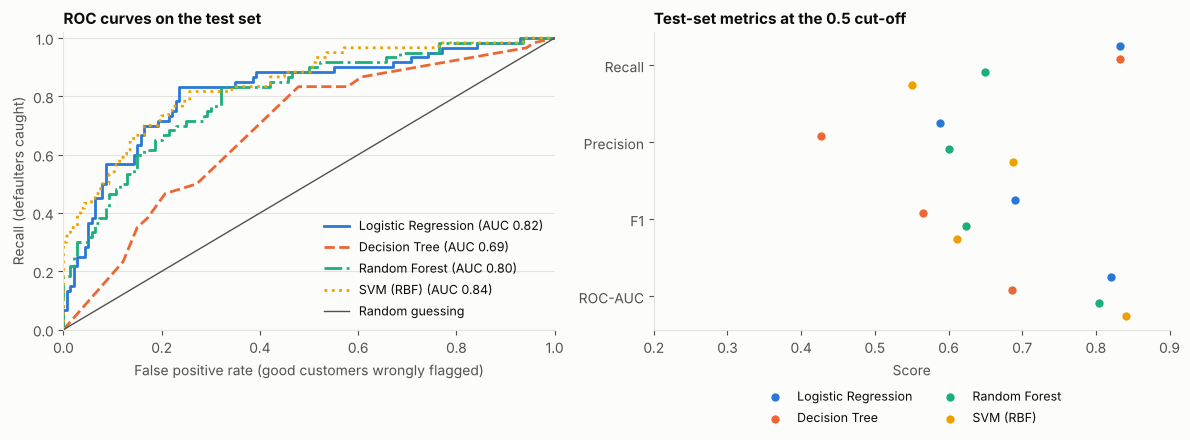

In [22]:
line_styles = {'Logistic Regression': (BLUE, '-'), 'Decision Tree': (ORANGE, '--'),
               'Random Forest': (AQUA, '-.'), 'SVM (RBF)': (YELLOW, ':')}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1, 1.05]})

ax = axes[0]
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    color, ls = line_styles[name]
    ax.plot(fpr, tpr, color=color, ls=ls, lw=2, label=f'{name} (AUC {roc_auc_score(y_test, p):.2f})')
ax.plot([0, 1], [0, 1], color=INK_2, lw=1, label='Random guessing')
ax.set(xlabel='False positive rate (good customers wrongly flagged)', ylabel='Recall (defaulters caught)',
       title='ROC curves on the test set', xlim=(0, 1), ylim=(0, 1.02))
ax.grid(axis='both')
ax.legend(loc='lower right', fontsize=9)

# Metric comparison as grouped dots: easier to compare than a table
ax = axes[1]
metrics_to_plot = ['recall', 'precision', 'f1', 'roc_auc']
ypos = np.arange(len(metrics_to_plot))
for k, (name, (color, _)) in enumerate(line_styles.items()):
    vals = [test_table.loc[name, m] for m in metrics_to_plot]
    ax.scatter(vals, ypos + (k - 1.5) * 0.17, s=64, color=color, edgecolor=SURFACE, linewidth=2, label=name, zorder=3)
ax.set_yticks(ypos, ['Recall', 'Precision', 'F1', 'ROC-AUC'])
ax.set(xlim=(0.2, 0.9), title='Test-set metrics at the 0.5 cut-off', xlabel='Score')
ax.invert_yaxis()
ax.grid(axis='x')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
finish('07_model_comparison')

### 5.5 Choosing the model
We pick the model with the best **cross-validated AUC on the training data**. This uses no test data, so the test
set stays an honest final exam, and AUC does not depend on any assumption about costs.

In [23]:
ranking = pd.Series({n: s.best_score_ for n, s in tuned.items()}).sort_values(ascending=False).round(4)
best_name = ranking.index[0]
best_pipe = tuned[best_name].best_estimator_
print('Cross-validated AUC ranking (training data only):')
print(ranking.to_string())
print(f'\nSelected model: {best_name}')

Cross-validated AUC ranking (training data only):
Random Forest          0.7976
SVM (RBF)              0.7960
Logistic Regression    0.7734
Decision Tree          0.6965

Selected model: Random Forest


**Reading the ranking honestly.** Random Forest, SVM and Logistic Regression are separated by less than their own fold-to-fold
variation (see the ± values in 5.2), so on this small dataset they are effectively tied. The Decision Tree is clearly the weakest.
The Random Forest is selected because the rule was fixed in advance (best cross-validated AUC), it handles mixed data and
non-linear effects without extra work, and it needs no feature scaling. Logistic Regression is the natural fallback if the
bank prefers a model whose every coefficient can be explained to a regulator.

### 5.6 Choosing the approve / decline cut-off
A model outputs a **probability of default**. The cut-off decides how cautious the bank is:
* a **low cut-off** flags many applicants. It catches more defaulters (high recall) but declines more good customers.
* a **high cut-off** flags few applicants. Fewer good customers are lost, but more defaulters slip through.

There is no single "correct" cut-off. It is a **business policy choice**. The brief makes recall the priority, so we set
an explicit policy: **catch at least 80% of defaulters, and, subject to that, decline as few good customers as possible.**
`RECALL_TARGET` is an adjustable assumption that the bank's risk team should confirm; the table below shows the alternatives.

For comparison we also show the cut-off that would minimise cost *if* approving a defaulter costs 5 times as much as declining a
good customer (the ratio published with the original German Credit data; again an assumption to be replaced with the bank's
own loss and margin figures).

The cut-off is chosen on **cross-validated predictions for the training set only**, so the test set plays no part.

In [24]:
RECALL_TARGET = 0.80     # POLICY ASSUMPTION: catch at least 80% of real defaulters


def threshold_curve(y_true, proba, thresholds=np.arange(0.05, 0.96, 0.01)):
    """Recall, precision, F1, share of good customers declined and cost at every cut-off."""
    y_true = np.asarray(y_true)
    rows = []
    for t in thresholds:
        flag = proba >= t
        tp, fp = (flag & (y_true == 1)).sum(), (flag & (y_true == 0)).sum()
        fn, tn = (~flag & (y_true == 1)).sum(), (~flag & (y_true == 0)).sum()
        rec = tp / (tp + fn)
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rows.append({'threshold': round(float(t), 2), 'recall': rec, 'precision': prec,
                     'f1': 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0,
                     'good_declined': fp / (fp + tn), 'cost': (fn * COST_FN + fp * COST_FP) / len(y_true)})
    curve = pd.DataFrame(rows)
    curve['cost_smooth'] = curve['cost'].rolling(5, center=True, min_periods=1).mean()   # damp sampling noise
    return curve


def pick_threshold(y_true, proba, recall_target=RECALL_TARGET):
    """Highest cut-off that still catches at least `recall_target` of defaulters (= fewest good customers declined)."""
    curve = threshold_curve(y_true, proba)
    ok = curve[curve['recall'] >= recall_target]
    return float(ok['threshold'].max()) if len(ok) else float(curve['threshold'].min())


def describe_cutoff(y_true, proba, t):
    """One row of the 'operating point' table."""
    r = evaluate(y_true, proba, t)
    return {'cut_off': round(float(t), 2), 'defaulters_caught': r['recall'], 'precision': r['precision'],
            'f1': r['f1'], 'good_customers_declined': r['FP'] / (r['FP'] + r['TN']),
            'applicants_flagged': (r['FP'] + r['TP']) / len(y_true), 'cost_per_applicant': r['cost_per_applicant']}


oof_train = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
curve = threshold_curve(y_train, oof_train)
t_star = pick_threshold(y_train, oof_train)
t_cost = float(curve.loc[curve['cost_smooth'].idxmin(), 'threshold'])

targets = sorted({0.70, 0.80, 0.90, RECALL_TARGET})
menu = {}
for r in targets:
    tag = '  <- chosen policy' if np.isclose(r, RECALL_TARGET) else ''
    menu[f'Catch at least {r:.0%} of defaulters{tag}'] = describe_cutoff(y_train, oof_train, pick_threshold(y_train, oof_train, r))
menu[f'Lowest cost ({COST_FN}:{COST_FP} cost ratio)'] = describe_cutoff(y_train, oof_train, t_cost)
menu['Approve everyone (no model)'] = describe_cutoff(y_train, oof_train, 1.01)
menu['Decline everyone'] = describe_cutoff(y_train, oof_train, 0.0)

print(f'Chosen cut-off: {t_star:.2f}  (cross-validated predictions on the training data)\n')
pd.DataFrame(menu).T.round(3)

Chosen cut-off: 0.38  (cross-validated predictions on the training data)



,cut_off,defaulters_caught,precision,f1,good_customers_declined,applicants_flagged,cost_per_applicant
Catch at least 70% of defaulters,0.47,0.700,0.573,0.630,0.223,0.366,0.606
Catch at least 80% of defaulters <- chosen policy,0.38,0.808,0.478,0.601,0.379,0.507,0.552
Catch at least 90% of defaulters,0.30,0.904,0.406,0.561,0.566,0.668,0.540
Lowest cost (5:1 cost ratio),0.24,0.975,0.379,0.546,0.684,0.771,0.516
Approve everyone (no model),1.01,0.000,0.000,0.000,0.000,0.000,1.500
Decline everyone,0.00,1.000,0.300,0.462,1.000,1.000,0.700


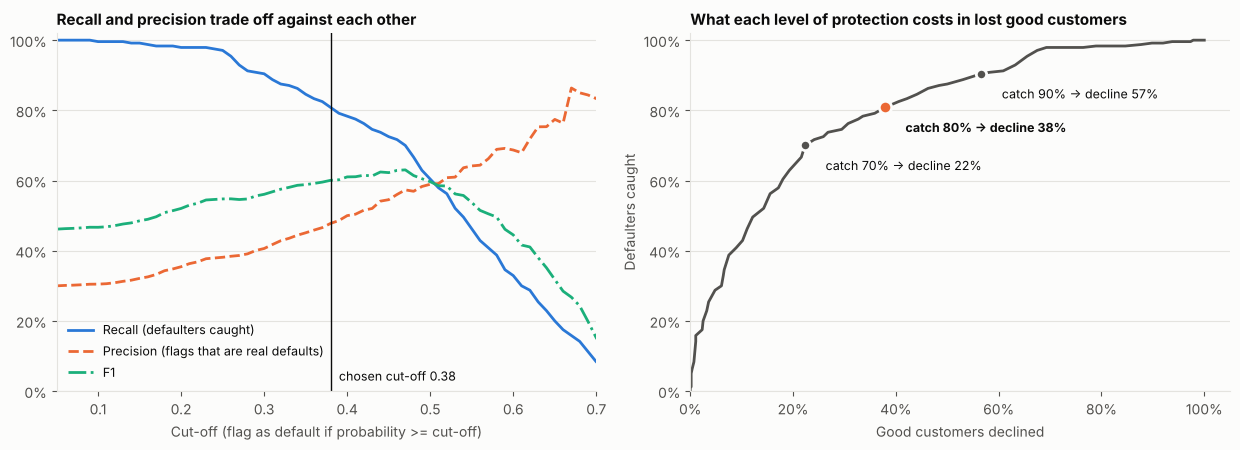

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
for col, color, ls, label in [('recall', BLUE, '-', 'Recall (defaulters caught)'),
                              ('precision', ORANGE, '--', 'Precision (flags that are real defaults)'),
                              ('f1', AQUA, '-.', 'F1')]:
    ax.plot(curve['threshold'], curve[col], color=color, ls=ls, lw=2, label=label)
ax.axvline(t_star, color=INK, lw=1)
ax.text(t_star + 0.01, 0.03, f'chosen cut-off {t_star:.2f}', fontsize=9)
ax.set(xlabel='Cut-off (flag as default if probability >= cut-off)', ylim=(0, 1.02), xlim=(0.05, 0.70),
       title='Recall and precision trade off against each other')
pct_axis(ax, 'y')
ax.grid(axis='both')
ax.legend(loc='lower left', fontsize=9)

ax = axes[1]
ax.plot(curve['good_declined'], curve['recall'], color=INK_2, lw=2)
for r in targets:
    row = curve.loc[curve['threshold'] == pick_threshold(y_train, oof_train, r)].iloc[0]
    chosen = np.isclose(r, RECALL_TARGET)
    ax.scatter([row['good_declined']], [row['recall']], s=80 if chosen else 55,
               color=ORANGE if chosen else INK_2, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"catch {r:.0%} -> decline {row['good_declined']:.0%}",
                (row['good_declined'], row['recall']), xytext=(row['good_declined'] + 0.04, row['recall'] - 0.07),
                fontsize=9, fontweight='bold' if chosen else 'normal')
ax.set(xlabel='Good customers declined', ylabel='Defaulters caught', xlim=(0, 1.05), ylim=(0, 1.02),
       title='What each level of protection costs in lost good customers')
pct_axis(ax, 'x')
pct_axis(ax, 'y')
ax.grid(axis='both')
finish('08_threshold_tuning')

### 5.7 Final test-set evaluation
The tuned model and the chosen cut-off are applied **once** to the 200 held-out applicants.

In [26]:
proba_test = best_pipe.predict_proba(X_test)[:, 1]
final_default_cut = evaluate(y_test, proba_test, 0.5)
final_tuned_cut = evaluate(y_test, proba_test, t_star)

final_compare = pd.DataFrame({'Default cut-off (0.50)': final_default_cut,
                              f'Tuned cut-off ({t_star:.2f})': final_tuned_cut}).T
print(f'Selected model: {best_name}\n')
final_compare['good_declined'] = final_compare['FP'] / (final_compare['FP'] + final_compare['TN'])
final_compare[['threshold', 'accuracy', 'recall', 'precision', 'f1', 'roc_auc', 'good_declined',
               'TN', 'FP', 'FN', 'TP']].round(3)

Selected model: Random Forest



,threshold,accuracy,recall,precision,f1,roc_auc,good_declined,TN,FP,FN,TP
Default cut-off (0.50),0.50,0.765,0.650,0.600,0.624,0.804,0.186,114.0,26.0,21.0,39.0
Tuned cut-off (0.38),0.38,0.660,0.833,0.463,0.595,0.804,0.414,82.0,58.0,10.0,50.0


              precision    recall  f1-score   support

   Good loan      0.891     0.586     0.707       140
     Default      0.463     0.833     0.595        60

    accuracy                          0.660       200
   macro avg      0.677     0.710     0.651       200
weighted avg      0.763     0.660     0.673       200



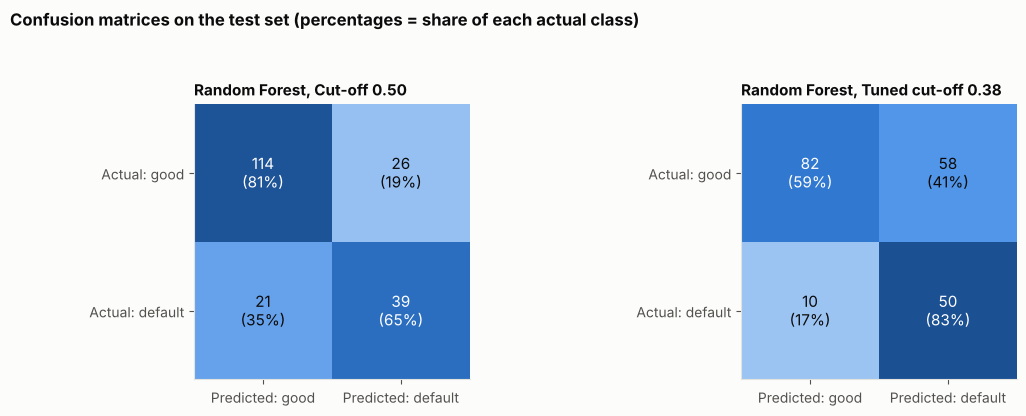

In [27]:
print(classification_report(y_test, (proba_test >= t_star).astype(int),
                            target_names=['Good loan', 'Default'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, thr, title in [(axes[0], 0.5, 'Cut-off 0.50'), (axes[1], t_star, f'Tuned cut-off {t_star:.2f}')]:
    cm = confusion_matrix(y_test, (proba_test >= thr).astype(int))
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap=SEQ_BLUE, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.0%})', ha='center', va='center', fontsize=11,
                    color='white' if pct[i, j] > 0.5 else INK)
    ax.set_xticks([0, 1], ['Predicted: good', 'Predicted: default'])
    ax.set_yticks([0, 1], ['Actual: good', 'Actual: default'])
    ax.set_title(f'{best_name}, {title}')
    ax.grid(False)
fig.suptitle('Confusion matrices on the test set (percentages = share of each actual class)',
             x=0.01, ha='left', fontweight='bold')
finish('09_confusion_matrices', rect=[0, 0, 1, 0.93])

### 5.8 How uncertain are these numbers?
The test set has only 200 applicants (60 defaulters), so a single score is noisy. A bootstrap (re-sampling the test set
1,000 times) gives a 95% range for each metric.

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb, pb = y_arr[idx], proba_test[idx]
    flag = pb >= t_star
    boot.append({'recall': recall_score(yb, flag), 'precision': precision_score(yb, flag, zero_division=0),
                 'f1': f1_score(yb, flag), 'roc_auc': roc_auc_score(yb, pb)})
boot = pd.DataFrame(boot)
ci = pd.DataFrame({'estimate': [final_tuned_cut[m] for m in boot.columns],
                   'ci_low (2.5%)': boot.quantile(0.025).values,
                   'ci_high (97.5%)': boot.quantile(0.975).values}, index=boot.columns)
ci.round(3)

,estimate,ci_low (2.5%),ci_high (97.5%)
recall,0.833,0.735,0.918
precision,0.463,0.367,0.558
f1,0.595,0.503,0.678
roc_auc,0.804,0.739,0.868


### 5.9 What drives the model's decisions?
**Permutation importance** shuffles one input at a time on the test set and measures how much the AUC drops. A big drop
means the model relies on that input. It works for any model type, so the same method is used regardless of the winner.

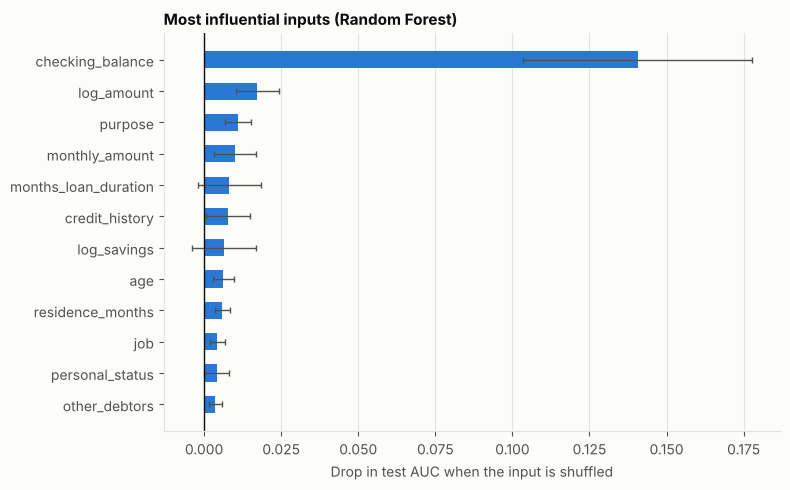

,importance,std
checking_balance,0.1406,0.0371
log_amount,0.0173,0.0069
purpose,0.0111,0.0042
monthly_amount,0.0100,0.0068
months_loan_duration,0.0082,0.0103
credit_history,0.0078,0.0070
log_savings,0.0065,0.0105
age,0.0063,0.0035
residence_months,0.0058,0.0024
job,0.0043,0.0025


In [29]:
perm = permutation_importance(best_pipe, X_test[FEATURES], y_test, scoring='roc_auc', n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=2)
importance = (pd.DataFrame({'importance': perm.importances_mean, 'std': perm.importances_std}, index=FEATURES)
                .sort_values('importance', ascending=False))
top = importance.head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top['importance'], xerr=top['std'], color=BLUE, height=0.55,
        error_kw={'ecolor': INK_2, 'elinewidth': 1, 'capsize': 2})
ax.axvline(0, color=INK, lw=1)
ax.set(xlabel='Drop in test AUC when the input is shuffled', title=f'Most influential inputs ({best_name})')
ax.grid(axis='y', visible=False)
finish('10_feature_importance')
importance.head(12).round(4)

## 6. Sensitive attributes: does the model need them?
The brief asks that good customers are not rejected unfairly. Four inputs describe *who the applicant is* rather than
*how they behave financially*: **gender**, **personal_status** (which is only recorded for male applicants, so it also encodes
gender), **age** and **foreign_worker**. Using them in a real lending decision can breach fair-lending rules in many
jurisdictions, so we test what they add. The Random Forest is re-trained with and without them, using the same settings and
5-fold cross-validation on the training data.

In [30]:
SENSITIVE = ['gender', 'personal_status', 'age', 'foreign_worker']
variants = {
    'All features': [],
    'Without gender + personal_status': ['gender', 'personal_status'],
    'Without age': ['age'],
    'Without foreign_worker': ['foreign_worker'],
    'Without all four sensitive': SENSITIVE,
}
rf_settings = {k.replace('clf__', ''): v for k, v in tuned['Random Forest'].best_params_.items()}

rows = {}
for label, drop in variants.items():
    num = [c for c in NUMERIC if c not in drop]
    cat = [c for c in CATEGORICAL if c not in drop]
    pipe = make_pipeline(RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                                random_state=RANDOM_STATE, **rf_settings), num, cat)
    oof = cross_val_predict(pipe, X_train[num + cat], y_train, cv=cv, method='predict_proba')[:, 1]
    t = pick_threshold(y_train, oof)
    row = describe_cutoff(y_train, oof, t)
    rows[label] = {'cv_auc': roc_auc_score(y_train, oof), 'cut_off_for_80%_recall': t,
                   'defaulters_caught': row['defaulters_caught'],
                   'good_customers_declined': row['good_customers_declined']}
    pipe.fit(X_train[num + cat], y_train)
    rows[label]['test_auc'] = roc_auc_score(y_test, pipe.predict_proba(X_test[num + cat])[:, 1])
sensitive_table = pd.DataFrame(rows).T
sensitive_table.round(3)

,cv_auc,cut_off_for_80%_recall,defaulters_caught,good_customers_declined,test_auc
All features,0.798,0.38,0.808,0.379,0.804
Without gender + personal_status,0.793,0.39,0.800,0.380,0.803
Without age,0.799,0.39,0.804,0.364,0.803
Without foreign_worker,0.797,0.38,0.817,0.377,0.799
Without all four sensitive,0.792,0.38,0.812,0.391,0.798


### 6.1 Does the chosen model treat groups differently?
Using the cross-validated predictions for the 800 training applicants (so each person is scored by a model that never saw them),
we compare, at the chosen cut-off, how many people in each group were flagged and how many **good** customers in each
group were wrongly flagged. Large gaps in the second column would mean one group of honest borrowers pays a higher price.

In [31]:
audit = X_train.copy()
audit['actual_default'] = y_train
audit['flagged'] = (oof_train >= t_star).astype(int)
audit['age_group'] = pd.cut(audit['age'], [0, 25, 35, 50, 120], labels=['under 25', '25-34', '35-49', '50+'])
audit['gender_group'] = audit['gender']


def group_audit(col):
    g = audit.groupby(col, observed=True)
    out = pd.DataFrame({
        'applicants': g.size(),
        'actual_default_rate': g['actual_default'].mean(),
        'flag_rate': g['flagged'].mean(),
        'defaulters_caught': g.apply(lambda d: d.loc[d.actual_default == 1, 'flagged'].mean()),
        'good_customers_wrongly_flagged': g.apply(lambda d: d.loc[d.actual_default == 0, 'flagged'].mean()),
    })
    return out


audit_table = pd.concat({c: group_audit(c) for c in ['gender_group', 'age_group', 'foreign_worker']})
audit_table.round(3)

applicants  actual_default_rate  flag_rate  defaulters_caught  good_customers_wrongly_flagged
gender_group   female           249                0.357      0.590              0.865                           0.438
               male             551                0.274      0.470              0.775                           0.355
age_group      under 25         146                0.411      0.712              0.900                           0.581
               25-34            332                0.292      0.479              0.784                           0.353
               35-49            238                0.239      0.433              0.789                           0.320
               50+               84                0.310      0.476              0.731                           0.362
foreign_worker no                31                0.097      0.290              1.000                           0.214
               yes              769                0.308      0.516              0.806                           0.387

## 7. Business impact

### 7.1 Risk bands: a basis for faster, more consistent approvals
Instead of a single approve / decline line, the probability can drive a **tiered workflow**. Applicants the model is
confident about are handled quickly, and human time is spent only where it adds value. Bands are shown on the test set.

In [32]:
bands = [0, 0.25, t_star, 0.60, 1.01]
band_labels = [f'Low (< {bands[1]:.2f})', f'Medium ({bands[1]:.2f} to {bands[2]:.2f})',
               f'High ({bands[2]:.2f} to {bands[3]:.2f})', f'Very high (>= {bands[3]:.2f})']
risk = pd.DataFrame({'proba': proba_test, 'default': y_test.to_numpy(), 'amount': loan_amount.loc[y_test.index].to_numpy()})
risk['band'] = pd.cut(risk['proba'], bands, labels=band_labels, right=False)
band_table = (risk.groupby('band', observed=True)
                  .agg(applicants=('default', 'size'), actual_default_rate=('default', 'mean'),
                       defaulters=('default', 'sum'), total_loan_value=('amount', 'sum')))
band_table['share_of_applicants'] = band_table['applicants'] / len(risk)
band_table[['applicants', 'share_of_applicants', 'actual_default_rate', 'defaulters', 'total_loan_value']].round(3)

,applicants,share_of_applicants,actual_default_rate,defaulters,total_loan_value
band,,,,,
Low (< 0.25),49,0.245,0.082,4,117156
Medium (0.25 to 0.38),43,0.215,0.140,6,132533
High (0.38 to 0.60),74,0.370,0.365,27,326023
Very high (>= 0.60),34,0.170,0.676,23,143873


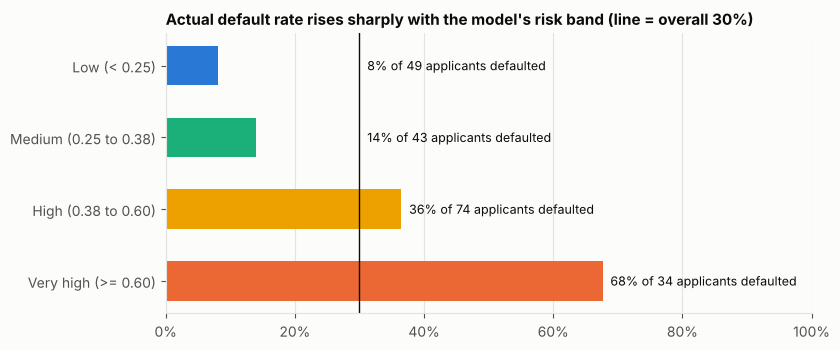

In [33]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
colors = [BLUE, AQUA, YELLOW, ORANGE]
ax.barh(band_table.index.astype(str), band_table['actual_default_rate'], color=colors, height=0.55)
for pos, (r, n) in enumerate(zip(band_table['actual_default_rate'], band_table['applicants'])):
    ax.text(max(r, 0.30) + 0.012, pos, f'{r:.0%} of {n} applicants defaulted', va='center', fontsize=9)
ax.axvline(y_test.mean(), color=INK, lw=1)
ax.set(xlim=(0, 1.0), title=f'Actual default rate rises sharply with the model\'s risk band (line = overall {y_test.mean():.0%})')
pct_axis(ax)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
finish('11_risk_bands')

### 7.2 Financial impact on the test set
Money terms use the **loan amount as the exposure** at risk when a borrower defaults (the brief states that a missed default
costs the full principal; no recoveries are assumed, which is conservative). Declining a good applicant forgoes that
loan's interest margin, which is **not in the data**, so we report the *volume* of good lending declined rather than inventing a profit figure.

In [34]:
test_amounts = loan_amount.loc[y_test.index].to_numpy()
y_t = y_test.to_numpy()
flag = proba_test >= t_star

exposure_total = test_amounts[y_t == 1].sum()
caught = test_amounts[(y_t == 1) & flag].sum()
missed = test_amounts[(y_t == 1) & ~flag].sum()
good_declined_value = test_amounts[(y_t == 0) & flag].sum()
good_total_value = test_amounts[y_t == 0].sum()

impact = pd.Series({
    'Applicants in test set': len(y_t),
    'Actual defaulters': int(y_t.sum()),
    'Defaulters flagged by model': int(((y_t == 1) & flag).sum()),
    'Defaulters missed': int(((y_t == 1) & ~flag).sum()),
    'Good customers flagged (false alarms)': int(((y_t == 0) & flag).sum()),
    'Loan value that defaulted, no model (approve all)': exposure_total,
    'Defaulted loan value flagged by model': caught,
    'Defaulted loan value still missed': missed,
    'Share of defaulted loan value flagged': caught / exposure_total,
    'Good-customer loan value flagged for review/decline': good_declined_value,
    'Share of good-customer loan value flagged': good_declined_value / good_total_value,
})
impact.map(lambda v: f'{v:,.0f}' if abs(v) >= 100 else (f'{v:.1%}' if isinstance(v, float) and v < 1.5 else f'{v:,.0f}'))

Applicants in test set                                     200
Actual defaulters                                           60
Defaulters flagged by model                                 50
Defaulters missed                                           10
Good customers flagged (false alarms)                       58
Loan value that defaulted, no model (approve all)      280,001
Defaulted loan value flagged by model                  259,305
Defaulted loan value still missed                       20,696
Share of defaulted loan value flagged                    92.6%
Good-customer loan value flagged for review/decline    210,591
Share of good-customer loan value flagged                47.9%
dtype: str

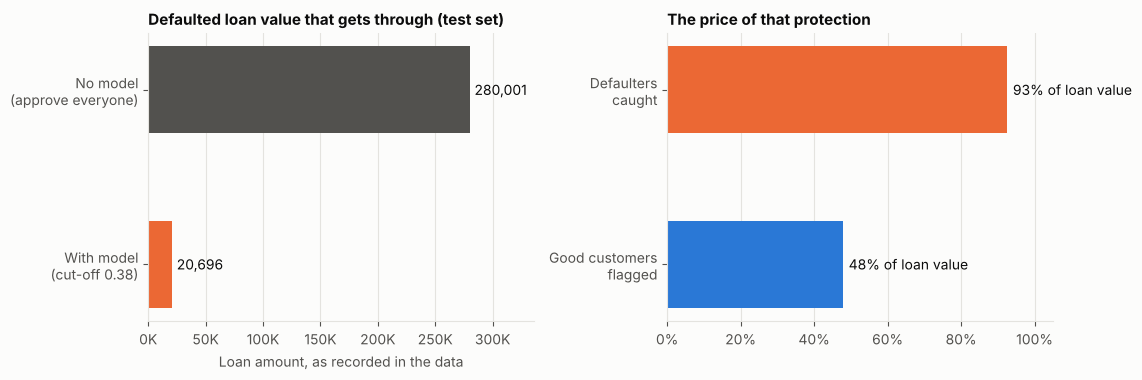

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax = axes[0]
vals = [exposure_total, missed]
ax.barh(['No model\n(approve everyone)', f'With model\n(cut-off {t_star:.2f})'], vals, color=[INK_2, ORANGE], height=0.5)
for pos, v in enumerate(vals):
    ax.text(v + exposure_total * 0.015, pos, f'{v:,.0f}', va='center')
ax.set(xlim=(0, exposure_total * 1.2), title='Defaulted loan value that gets through (test set)', xlabel='Loan amount, as recorded in the data')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}K'))
ax.invert_yaxis()
ax.grid(axis='y', visible=False)

ax = axes[1]
labels = ['Defaulters\ncaught', 'Good customers\nflagged']
shares = [caught / exposure_total, good_declined_value / good_total_value]
ax.barh(labels, shares, color=[ORANGE, BLUE], height=0.5)
for pos, v in enumerate(shares):
    ax.text(v + 0.015, pos, f'{v:.0%} of loan value', va='center')
ax.set(xlim=(0, 1.05), title='The price of that protection')
pct_axis(ax)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
finish('12_financial_impact')

### 7.3 Save the final model and key results
The fitted pipeline (cleaning of numbers, imputation, encoding and the Random Forest) is saved so it can score new applicants.
The headline numbers are written to `results/key_results.json` for the presentation.

In [36]:
joblib.dump({'pipeline': best_pipe, 'features': FEATURES, 'threshold': t_star, 'model_name': best_name},
            RES_DIR / 'credit_default_model.joblib')

key_results = {
    'n_applicants': int(len(data)), 'default_rate': float(data[TARGET].mean()),
    'selected_model': best_name, 'cut_off': t_star, 'recall_target': RECALL_TARGET,
    'cost_ratio_assumed': f'{COST_FN}:{COST_FP}',
    'cv_auc': {n: float(s.best_score_) for n, s in tuned.items()},
    'test_table_at_0.5': test_table[['accuracy', 'recall', 'precision', 'f1', 'roc_auc']].round(4).to_dict('index'),
    'final_default_cut': {k: float(v) for k, v in final_default_cut.items()},
    'final_tuned_cut': {k: float(v) for k, v in final_tuned_cut.items()},
    'bootstrap_ci': ci.round(4).to_dict('index'),
    'top_features': importance.head(8)['importance'].round(4).to_dict(),
    'sensitive_table': sensitive_table.round(4).to_dict('index'),
    'risk_bands': band_table.round(4).reset_index().astype({'band': str}).to_dict('records'),
    'impact': {k: float(v) for k, v in impact.items()},
}
(RES_DIR / 'key_results.json').write_text(json.dumps(key_results, indent=2, default=float))
test_table.round(4).to_csv(RES_DIR / 'test_metrics_by_model.csv')
pd.DataFrame(menu).T.round(4).to_csv(RES_DIR / 'cutoff_options.csv')
print('Saved:', sorted(p.name for p in RES_DIR.iterdir()))

Saved: ['credit_default_model.joblib', 'cutoff_options.csv', 'key_results.json', 'test_metrics_by_model.csv']


**What sections 6 and 6.1 show**
* Removing all four sensitive inputs changes cross-validated AUC from 0.798 to 0.792 and test AUC from 0.804 to 0.798. That
  is well inside the noise of a 1,000-row dataset, so **the model does not need these attributes**.
* The audit still shows uneven false alarms even for a model that sees age and gender: among *good* customers, 58% of those
  under 25 and 44% of women are flagged, against 32% to 36% for other groups. Part of this reflects genuinely different default
  rates (41% for under-25s, 36% for women), but the gap in wrongly flagged good customers is the fairness risk the brief warns about.
* Group sizes are small (e.g. 31 non-foreign workers), so these differences are indicative, not proof.

**Recommendation:** train the production model *without* gender, personal_status, age and foreign_worker, and repeat this
group audit on every retrain. Age is also not a legitimate basis for credit decisions in many jurisdictions; legal and
compliance teams should confirm which attributes are permitted.

## 8. Conclusions and recommendations

### What we found
1. **Who defaults.** 30% of loans default. The strongest signals are the **checking-account status** (by far the most
   influential input), then **loan amount and duration** (bigger, longer loans default more), **purpose**, and **credit history**.
   Applicants with no checking-account record default far *less* (12%) than those with one (42%), so "missing" is itself informative.
2. **Counter-intuitive pattern worth a business check.** Applicants with a "critical" credit history default *less* (17%) than those
   who "fully repaid" earlier loans (57% to 62%). The labels in this dataset may not mean what they appear to; the bank should confirm how
   the field is recorded before relying on it.
3. **Model choice.** Random Forest, SVM and Logistic Regression perform about the same (cross-validated AUC 0.77 to 0.80).
   The Decision Tree is clearly worse (0.70). Accuracy is a poor yardstick here: an "approve everyone" rule scores 70%.
4. **Cut-off.** At the default 0.50 cut-off the Random Forest catches only 65% of defaulters on the test set. Lowering the cut-off to
   0.38 (chosen on training data to catch at least 80% of defaulters) catches **83% of defaulters (50 of 60) and
   about 93% of the defaulted loan value**, at the price of flagging **41% of good applicants**.
5. **Uncertainty.** With only 200 test applicants, the 95% range for recall is roughly 74% to 92% and for AUC 0.74 to 0.87.
   The conclusions are directionally solid but the exact figures will move on new data.

### How the bank could use it
* **Low and medium risk bands (about 46% of applicants, 8% to 14% default rate): fast-track approval.** This is where the
  faster-approval benefit comes from.
* **High band (37% of applicants, about 36% default rate): manual review, or approve with tighter terms** (lower amount,
  shorter duration, guarantor) rather than outright rejection. This limits unfair rejection of good customers.
* **Very high band (17% of applicants, ~68% default rate): decline or escalate.**

### Limitations and next steps
* Only 1,000 applicants, so results are noisy. Re-validate on a larger, more recent sample before go-live.
* The 80% recall target and the 5:1 cost ratio are assumptions; the bank's own loss and margin numbers should set them.
* The data only contains approved loans (we never see what would have happened to rejected applicants), which can bias any
  model trained on it.
* Monitor the model monthly for drift, and repeat the fairness audit with each retrain.